In [ ]:
%pip install -r dinov2/requirements.txt
%pip install torch
%pip install numpy
%pip install matplotlib
%pip install torchvision
%pip install tqdm
%pip install transformers[torch]

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com, https://download.pytorch.org/whl/cu117, https://pypi.nvidia.com
     |█████████████████████▎          | 1223.2 MB 21.4 MB/s eta 0:00:29  |▉                               | 46.4 MB 3.2 MB/s eta 0:09:17     |█                               | 53.0 MB 3.2 MB/s eta 0:09:15     |████▏                           | 237.8 MB 81.6 MB/s eta 0:00:20█▎                          | 305.7 MB 33.4 MB/s eta 0:00:47     |███████▌                        | 430.3 MB 8.0 MB/s eta 0:02:58     |███████▉                        | 450.2 MB 11.7 MB/s eta 0:02:00     |███████▉                        | 452.9 MB 11.7 MB/s eta 0:02:00     |█████████▌                      | 545.4 MB 5.3 MB/s eta 0:04:05     |█████████▊                      | 561.5 MB 58.0 MB/s eta 0:00:23     |███████████▋                    | 670.4 MB 55.3 MB/s eta 0:00:22     |███████████▊              

In [1]:
%pip install scikit-learn --upgrade

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
     |████████████████████████████████| 11.1 MB 8.5 MB/s eta 0:00:01
     |████████████████████████████████| 301 kB 49.3 MB/s eta 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
smac 0.13.1 requires dask, which is not installed.
smac 0.13.1 requires distributed, which is not installed.
auto-sklearn 0.10.0 requires dask, which is not installed.
auto-sklearn 0.10.0 requires distributed, which is not installed.
auto-sklearn 0.10.0 requires lockfile, which is not installed.
auto-sklearn 0.10.0 requires pandas<1.0, but you have pandas 1.3.5 which is incompatible.
auto-sklearn 0.10.0 requires scikit-learn<0.23,>=0.22.0, but you have scikit-learn 1.3.2 which is incompatible.
Note: you may need to restart the ker

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
import numpy as np
import random
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import os
from sklearn.model_selection import train_test_split

# Setting Hyperparameters

In [2]:
BATCH_SIZE = 128
EPOCHS = 100 # Try increasing epochs to 30
LEARNING_RATE = 3e-4
PATCH_SIZE = 4
NUM_CLASSES = 3
IMAGE_SIZE = 224 # Transform the image and make the size go to 224
CHANNELS = 3
EMBED_DIM = 256
NUM_HEADS = 8 # INcrease the number heads
DEPTH = 6
MLP_DIM = 512
DROP_RATE = 0.1

## 5. Define Image Transformations

In [3]:
# Copyright (c) Meta Platforms, Inc. and affiliates.
#
# This source code is licensed under the Apache License, Version 2.0
# found in the LICENSE file in the root directory of this source tree.

from typing import Sequence

import torch
from torchvision import transforms


class GaussianBlur(transforms.RandomApply):
    """
    Apply Gaussian Blur to the PIL image.
    """

    def __init__(self, *, p: float = 0.5, radius_min: float = 0.1, radius_max: float = 2.0):
        # NOTE: torchvision is applying 1 - probability to return the original image
        keep_p = 1 - p
        transform = transforms.GaussianBlur(kernel_size=9, sigma=(radius_min, radius_max))
        super().__init__(transforms=[transform], p=keep_p)


class MaybeToTensor(transforms.ToTensor):
    """
    Convert a ``PIL Image`` or ``numpy.ndarray`` to tensor, or keep as is if already a tensor.
    """

    def __call__(self, pic):
        """
        Args:
            pic (PIL Image, numpy.ndarray or torch.tensor): Image to be converted to tensor.
        Returns:
            Tensor: Converted image.
        """
        if isinstance(pic, torch.Tensor):
            return pic
        return super().__call__(pic)


# Use timm's names
IMAGENET_DEFAULT_MEAN = (0.485, 0.456, 0.406)
IMAGENET_DEFAULT_STD = (0.229, 0.224, 0.225)


def make_normalize_transform(
    mean: Sequence[float] = IMAGENET_DEFAULT_MEAN,
    std: Sequence[float] = IMAGENET_DEFAULT_STD,
) -> transforms.Normalize:
    return transforms.Normalize(mean=mean, std=std)


# This roughly matches torchvision's preset for classification training:
#   https://github.com/pytorch/vision/blob/main/references/classification/presets.py#L6-L44
def make_classification_train_transform(
    *,
    crop_size: int = 224,
    interpolation=transforms.InterpolationMode.BICUBIC,
    hflip_prob: float = 0.5,
    mean: Sequence[float] = IMAGENET_DEFAULT_MEAN,
    std: Sequence[float] = IMAGENET_DEFAULT_STD,
):
    transforms_list = [transforms.RandomResizedCrop(crop_size, interpolation=interpolation)]
    if hflip_prob > 0.0:
        transforms_list.append(transforms.RandomHorizontalFlip(hflip_prob))
    transforms_list.extend(
        [
            MaybeToTensor(),
            make_normalize_transform(mean=mean, std=std),
        ]
    )
    return transforms.Compose(transforms_list)


# This matches (roughly) torchvision's preset for classification evaluation:
#   https://github.com/pytorch/vision/blob/main/references/classification/presets.py#L47-L69
def make_classification_eval_transform(
    *,
    resize_size: int = 256,
    interpolation=transforms.InterpolationMode.BICUBIC,
    crop_size: int = 224,
    mean: Sequence[float] = IMAGENET_DEFAULT_MEAN,
    std: Sequence[float] = IMAGENET_DEFAULT_STD,
) -> transforms.Compose:
    transforms_list = [
        transforms.Resize(resize_size, interpolation=interpolation),
        transforms.CenterCrop(crop_size),
        MaybeToTensor(),
        make_normalize_transform(mean=mean, std=std),
    ]
    return transforms.Compose(transforms_list)


In [4]:
transform = make_classification_train_transform()

transform_train = make_classification_eval_transform()

## Load Dataset

In [5]:
class GrapeVineClassificationDataset(Dataset):
    """Dataset for grapevine disease classification for YOLO + Model """

    def __init__(self, root_dir, split='train', val_size=0.2, test_size=0.1, transform=None):
        """Arguments:
            root_dir: Directory for images
            classes: Class name of the dataset, defined by folder's name
            split: Which split to use: train, val, test
            val_size: Portion for validation split of the dataset
            test_size: Portion for test split of the dataset
            transform: Optional transform to be applied on the images
        """
        self.root_dir = root_dir
        self.transform = transform

        self.classes = os.listdir(root_dir)
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)} 

        self.image_paths = []
        self.labels = [] 

        self.number_of_image = 0
        for cls_name in self.classes: 
            self.number_of_image += len(os.listdir(os.path.join(root_dir, cls_name)))

        for cls_name in self.classes:
            cls_path = os.path.join(root_dir, cls_name)
            for img_name in os.listdir(cls_path):
                if img_name.endswith('.JPG'):

                    self.image_paths.append(os.path.join(cls_path, img_name))  
                    self.labels.append(self.class_to_idx[cls_name])

        # Convert to numpy arrays for easier indexing
        self.image_paths = np.array(self.image_paths)
        self.labels = np.array(self.labels)


        # Split the dataset into train, validation, and test sets
        self.train_paths, self.temp_paths, self.train_labels, self.temp_labels = train_test_split(
            self.image_paths, self.labels, test_size=(val_size + test_size), random_state=42, stratify=self.labels)


        self.val_paths, self.test_paths, self.val_labels, self.test_labels = train_test_split(
            self.temp_paths, self.temp_labels, test_size=test_size/(val_size + test_size), random_state=42, stratify=self.temp_labels)


        # Select the appropriate split
        if split == 'train':
            self.image_paths, self.labels = self.train_paths, self.train_labels
        elif split == 'val':
            self.image_paths, self.labels = self.val_paths, self.val_labels
        elif split == 'test':
            self.image_paths, self.labels = self.test_paths, self.test_labels
        else:
            raise ValueError("Split must be 'train', 'val', or 'test'.")


        print(f"Number of images in {split} split: {len(self.image_paths)}")

       
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):

        img_path = self.image_paths[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = self.labels[idx]  

        if self.transform:
            image = Image.fromarray(image) 
            image = self.transform(image)


        return image, label  
    

    def get_classes(self):

        return self.classes

Number of images in train split: 59301
['BlackRot', 'Esca', 'LeafBlight']


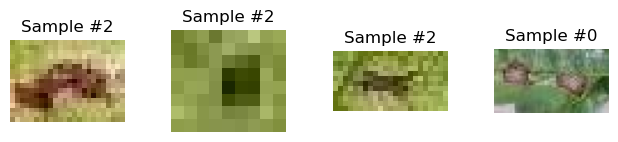

In [10]:
grape_dataset = GrapeVineClassificationDataset(root_dir="../Datasets/DatasetClassification/", split='train', val_size=0.2, test_size=0.1)

print(grape_dataset.get_classes())

fig = plt.figure()

i = 0
for image, label in grape_dataset:

    ax = plt.subplot(1, 4, i + 1)
    plt.tight_layout()
    ax.set_title("Sample #{}".format(label))
    ax.axis("off")
    #COnvert to see the image
    plt.imshow(image)

    if i == 3:
        plt.show()
        break

    i+=1

## Load Dataset

In [6]:
train_dataset = GrapeVineClassificationDataset(root_dir="../Datasets/DatasetClassificationWithDataAugment/", split='train', val_size=0.2, test_size=0.1,
                                 transform=transform_train)

val_dataset = GrapeVineClassificationDataset(root_dir="../Datasets/DatasetClassificationWithDataAugment/", split='val', val_size=0.2, test_size=0.1,
                                 transform=transform)   

test_dataset = GrapeVineClassificationDataset(root_dir="../Datasets/DatasetClassificationWithDataAugment/", split='test', val_size=0.2, test_size=0.1,
                                 )

Number of images in train split: 83999
Number of images in val split: 24000
Number of images in test split: 12001


In [7]:
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=BATCH_SIZE,
                          shuffle=True)

val_loader = DataLoader(dataset=val_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=False)

test_loader = DataLoader(dataset=test_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=False)

In [8]:
# Let's check out what we've created
print(f"DataLoader: {train_loader, test_loader}")
print(f"Length of train_loader: {len(train_loader)} batches of {BATCH_SIZE}...")
print(f"Length of val_loader: {len(val_loader)} batches of {BATCH_SIZE}...")
print(f"Length of test_loader: {len(test_loader)} batches of {BATCH_SIZE}...")

DataLoader: (<torch.utils.data.dataloader.DataLoader object at 0x7fbd438bef70>, <torch.utils.data.dataloader.DataLoader object at 0x7fbd438be940>)
Length of train_loader: 657 batches of 128...
Length of val_loader: 188 batches of 128...
Length of test_loader: 94 batches of 128...


## Load model

In [9]:
device = "cuda:1"  if torch.cuda.is_available() else "cpu"
print(f"Using Device: {device}")

Using Device: cuda:1


In [17]:
from transformers import AutoImageProcessor, Dinov2ForImageClassification
import torch
from PIL import Image

# Load the pre-trained model and image processor
processor = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
model = Dinov2ForImageClassification.from_pretrained("facebook/dinov2-base", num_labels=3).to(device)

for param in model.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True



# Set the model to evaluation mode
#model.eval()
model.train()

Some weights of Dinov2ForImageClassification were not initialized from the model checkpoint at facebook/dinov2-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Dinov2ForImageClassification(
  (dinov2): Dinov2Model(
    (embeddings): Dinov2Embeddings(
      (patch_embeddings): Dinov2PatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): Dinov2Encoder(
      (layer): ModuleList(
        (0-11): 12 x Dinov2Layer(
          (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (attention): Dinov2Attention(
            (attention): Dinov2SelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): Dinov2SelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
       

In [18]:
model.classifier

Linear(in_features=1536, out_features=3, bias=True)

In [19]:
criterion = nn.CrossEntropyLoss() # Measure how wrong our model is
optimizer = torch.optim.Adam(params=model.parameters(), # update our model's parameters to try and reduce the loss
                             lr=LEARNING_RATE)

In [20]:
import pandas as pd

def train(model, loader, optimizer, criterion):
    # Set the mode of the model into training
    model.train()

    total_loss, correct = 0, 0 

    for x, y in loader:         
 
        # Moving (Sending) our data into the target device
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        # 1. Forward pass (model outputs raw logits)
        out = model(x)['logits'] 
        # 2. Calculate loss (per batch)
        loss = criterion(out, y)
        # 3. Perform backpropgation
        loss.backward()
        # 4. Perforam Gradient Descent
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()

    # You have to scale the loss (Normlization step to make the loss general across all batches)
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

def evaluate(model, loader):
    model.eval() # Set the mode of the model into evlauation
    correct = 0
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)['logits'] 
            correct += (out.argmax(dim=1) == y).sum().item()
    return correct / len(loader.dataset)

In [21]:
from tqdm.auto import tqdm

### Training
train_accuracies, test_accuracies = [], []
train_losses = [] 

for epoch in tqdm(range(EPOCHS)):
    train_loss, train_acc = train(model, train_loader, optimizer, criterion)
    train_losses.append(train_loss)
    test_acc = evaluate(model, val_loader)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    print(f"Epoch: {epoch+1}/{EPOCHS}, Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}%, Test acc: {test_acc:.4f}")

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch: 1/100, Train loss: 0.3748, Train acc: 0.8544%, Test acc: 0.8315
Epoch: 2/100, Train loss: 0.2877, Train acc: 0.8889%, Test acc: 0.8356
Epoch: 3/100, Train loss: 0.2737, Train acc: 0.8953%, Test acc: 0.8360
Epoch: 4/100, Train loss: 0.2666, Train acc: 0.8980%, Test acc: 0.8353
Epoch: 5/100, Train loss: 0.2611, Train acc: 0.9001%, Test acc: 0.8414
Epoch: 6/100, Train loss: 0.2581, Train acc: 0.9009%, Test acc: 0.8407
Epoch: 7/100, Train loss: 0.2538, Train acc: 0.9034%, Test acc: 0.8414
Epoch: 8/100, Train loss: 0.2512, Train acc: 0.9035%, Test acc: 0.8385
Epoch: 9/100, Train loss: 0.2496, Train acc: 0.9041%, Test acc: 0.8407
Epoch: 10/100, Train loss: 0.2476, Train acc: 0.9047%, Test acc: 0.8348
Epoch: 11/100, Train loss: 0.2463, Train acc: 0.9054%, Test acc: 0.8460
Epoch: 12/100, Train loss: 0.2448, Train acc: 0.9058%, Test acc: 0.8380
Epoch: 13/100, Train loss: 0.2433, Train acc: 0.9072%, Test acc: 0.8454
Epoch: 14/100, Train loss: 0.2431, Train acc: 0.9072%, Test acc: 0.8421
E

Output

Epoch: 1/100, Train loss: 0.7921, Train acc: 0.6520%, Test acc: 0.8437
Epoch: 2/100, Train loss: 0.3922, Train acc: 0.8437%, Test acc: 0.8524
Epoch: 3/100, Train loss: 0.3484, Train acc: 0.8637%, Test acc: 0.8768
Epoch: 4/100, Train loss: 0.3252, Train acc: 0.8734%, Test acc: 0.8857
Epoch: 5/100, Train loss: 0.3015, Train acc: 0.8825%, Test acc: 0.8811
Epoch: 6/100, Train loss: 0.2926, Train acc: 0.8856%, Test acc: 0.8885
Epoch: 7/100, Train loss: 0.2810, Train acc: 0.8906%, Test acc: 0.8938
Epoch: 8/100, Train loss: 0.2744, Train acc: 0.8944%, Test acc: 0.9003
Epoch: 9/100, Train loss: 0.2649, Train acc: 0.8977%, Test acc: 0.9004
Epoch: 10/100, Train loss: 0.2628, Train acc: 0.8991%, Test acc: 0.9044
Epoch: 11/100, Train loss: 0.2563, Train acc: 0.9012%, Test acc: 0.9010
Epoch: 12/100, Train loss: 0.2502, Train acc: 0.9042%, Test acc: 0.9054
Epoch: 13/100, Train loss: 0.2460, Train acc: 0.9048%, Test acc: 0.8944
Epoch: 14/100, Train loss: 0.2432, Train acc: 0.9058%, Test acc: 0.9059
Epoch: 15/100, Train loss: 0.2383, Train acc: 0.9093%, Test acc: 0.9109
Epoch: 16/100, Train loss: 0.2348, Train acc: 0.9084%, Test acc: 0.9072
Epoch: 17/100, Train loss: 0.2311, Train acc: 0.9109%, Test acc: 0.9053
Epoch: 18/100, Train loss: 0.2244, Train acc: 0.9139%, Test acc: 0.9082
Epoch: 19/100, Train loss: 0.2204, Train acc: 0.9148%, Test acc: 0.9070
Epoch: 20/100, Train loss: 0.2198, Train acc: 0.9149%, Test acc: 0.9085
Epoch: 21/100, Train loss: 0.2164, Train acc: 0.9160%, Test acc: 0.9034
Epoch: 22/100, Train loss: 0.2157, Train acc: 0.9174%, Test acc: 0.9121
Epoch: 23/100, Train loss: 0.2084, Train acc: 0.9190%, Test acc: 0.9067
Epoch: 24/100, Train loss: 0.2064, Train acc: 0.9204%, Test acc: 0.9072
Epoch: 25/100, Train loss: 0.2019, Train acc: 0.9223%, Test acc: 0.9102
Epoch: 26/100, Train loss: 0.1983, Train acc: 0.9233%, Test acc: 0.9103
Epoch: 27/100, Train loss: 0.1957, Train acc: 0.9246%, Test acc: 0.9130
Epoch: 28/100, Train loss: 0.1973, Train acc: 0.9224%, Test acc: 0.9081
Epoch: 29/100, Train loss: 0.1910, Train acc: 0.9262%, Test acc: 0.9095
Epoch: 30/100, Train loss: 0.1894, Train acc: 0.9265%, Test acc: 0.9058
Epoch: 31/100, Train loss: 0.1837, Train acc: 0.9286%, Test acc: 0.9129
Epoch: 32/100, Train loss: 0.1816, Train acc: 0.9295%, Test acc: 0.9126
Epoch: 33/100, Train loss: 0.1782, Train acc: 0.9306%, Test acc: 0.9079
Epoch: 34/100, Train loss: 0.1758, Train acc: 0.9309%, Test acc: 0.9159
Epoch: 35/100, Train loss: 0.1727, Train acc: 0.9333%, Test acc: 0.9175
Epoch: 36/100, Train loss: 0.1706, Train acc: 0.9327%, Test acc: 0.9150
Epoch: 37/100, Train loss: 0.1668, Train acc: 0.9355%, Test acc: 0.9133
Epoch: 38/100, Train loss: 0.1632, Train acc: 0.9354%, Test acc: 0.9155
Epoch: 39/100, Train loss: 0.1607, Train acc: 0.9381%, Test acc: 0.9063
Epoch: 40/100, Train loss: 0.1583, Train acc: 0.9382%, Test acc: 0.9135
Epoch: 41/100, Train loss: 0.1590, Train acc: 0.9383%, Test acc: 0.9184
Epoch: 42/100, Train loss: 0.1498, Train acc: 0.9420%, Test acc: 0.9187
Epoch: 43/100, Train loss: 0.1469, Train acc: 0.9432%, Test acc: 0.9144
Epoch: 44/100, Train loss: 0.1452, Train acc: 0.9433%, Test acc: 0.9191
Epoch: 45/100, Train loss: 0.1378, Train acc: 0.9456%, Test acc: 0.9183
Epoch: 46/100, Train loss: 0.1374, Train acc: 0.9461%, Test acc: 0.9098
Epoch: 47/100, Train loss: 0.1312, Train acc: 0.9496%, Test acc: 0.9153
Epoch: 48/100, Train loss: 0.1268, Train acc: 0.9504%, Test acc: 0.9122
Epoch: 49/100, Train loss: 0.1249, Train acc: 0.9511%, Test acc: 0.9147
Epoch: 50/100, Train loss: 0.1209, Train acc: 0.9537%, Test acc: 0.9155
Epoch: 51/100, Train loss: 0.1191, Train acc: 0.9528%, Test acc: 0.9178
Epoch: 52/100, Train loss: 0.1110, Train acc: 0.9572%, Test acc: 0.9135
Epoch: 53/100, Train loss: 0.1115, Train acc: 0.9560%, Test acc: 0.9153
Epoch: 54/100, Train loss: 0.1092, Train acc: 0.9568%, Test acc: 0.9175
Epoch: 55/100, Train loss: 0.1007, Train acc: 0.9610%, Test acc: 0.9187
Epoch: 56/100, Train loss: 0.0992, Train acc: 0.9617%, Test acc: 0.9133
Epoch: 57/100, Train loss: 0.0928, Train acc: 0.9646%, Test acc: 0.9174
Epoch: 58/100, Train loss: 0.0908, Train acc: 0.9649%, Test acc: 0.9167
Epoch: 59/100, Train loss: 0.0874, Train acc: 0.9657%, Test acc: 0.9113
Epoch: 60/100, Train loss: 0.0833, Train acc: 0.9680%, Test acc: 0.9182
Epoch: 61/100, Train loss: 0.0816, Train acc: 0.9684%, Test acc: 0.9159
Epoch: 62/100, Train loss: 0.0776, Train acc: 0.9706%, Test acc: 0.9161
Epoch: 63/100, Train loss: 0.0763, Train acc: 0.9708%, Test acc: 0.9153
Epoch: 64/100, Train loss: 0.0702, Train acc: 0.9729%, Test acc: 0.9158
Epoch: 65/100, Train loss: 0.0673, Train acc: 0.9747%, Test acc: 0.9191
Epoch: 66/100, Train loss: 0.0685, Train acc: 0.9731%, Test acc: 0.9169
Epoch: 67/100, Train loss: 0.0630, Train acc: 0.9760%, Test acc: 0.9118
Epoch: 68/100, Train loss: 0.0627, Train acc: 0.9763%, Test acc: 0.9153
Epoch: 69/100, Train loss: 0.0589, Train acc: 0.9772%, Test acc: 0.9170
Epoch: 70/100, Train loss: 0.0532, Train acc: 0.9797%, Test acc: 0.9160
Epoch: 71/100, Train loss: 0.0564, Train acc: 0.9786%, Test acc: 0.9123
Epoch: 72/100, Train loss: 0.0530, Train acc: 0.9803%, Test acc: 0.9161
Epoch: 73/100, Train loss: 0.0477, Train acc: 0.9828%, Test acc: 0.9124
Epoch: 74/100, Train loss: 0.0493, Train acc: 0.9815%, Test acc: 0.9126
Epoch: 75/100, Train loss: 0.0442, Train acc: 0.9831%, Test acc: 0.9129
Epoch: 76/100, Train loss: 0.0595, Train acc: 0.9789%, Test acc: 0.9149
Epoch: 77/100, Train loss: 0.0579, Train acc: 0.9786%, Test acc: 0.9159
Epoch: 78/100, Train loss: 0.0407, Train acc: 0.9850%, Test acc: 0.9150
Epoch: 79/100, Train loss: 0.0402, Train acc: 0.9851%, Test acc: 0.9161
Epoch: 80/100, Train loss: 0.0360, Train acc: 0.9866%, Test acc: 0.9156
Epoch: 81/100, Train loss: 0.0393, Train acc: 0.9851%, Test acc: 0.9150
Epoch: 82/100, Train loss: 0.0385, Train acc: 0.9857%, Test acc: 0.9165
Epoch: 83/100, Train loss: 0.0379, Train acc: 0.9861%, Test acc: 0.9144
Epoch: 84/100, Train loss: 0.0364, Train acc: 0.9867%, Test acc: 0.9144
Epoch: 85/100, Train loss: 0.0348, Train acc: 0.9871%, Test acc: 0.9165
Epoch: 86/100, Train loss: 0.0332, Train acc: 0.9883%, Test acc: 0.9155
Epoch: 87/100, Train loss: 0.0355, Train acc: 0.9871%, Test acc: 0.9148
Epoch: 88/100, Train loss: 0.0288, Train acc: 0.9893%, Test acc: 0.9117
Epoch: 89/100, Train loss: 0.0335, Train acc: 0.9872%, Test acc: 0.9150
Epoch: 90/100, Train loss: 0.0288, Train acc: 0.9892%, Test acc: 0.9132
Epoch: 91/100, Train loss: 0.0313, Train acc: 0.9887%, Test acc: 0.9134
Epoch: 92/100, Train loss: 0.0306, Train acc: 0.9888%, Test acc: 0.9155
Epoch: 93/100, Train loss: 0.0293, Train acc: 0.9896%, Test acc: 0.9162
Epoch: 94/100, Train loss: 0.0283, Train acc: 0.9893%, Test acc: 0.9169
Epoch: 95/100, Train loss: 0.0255, Train acc: 0.9911%, Test acc: 0.9137
Epoch: 96/100, Train loss: 0.0290, Train acc: 0.9894%, Test acc: 0.9174
Epoch: 97/100, Train loss: 0.0266, Train acc: 0.9908%, Test acc: 0.9141
Epoch: 98/100, Train loss: 0.0256, Train acc: 0.9905%, Test acc: 0.9150
Epoch: 99/100, Train loss: 0.0245, Train acc: 0.9912%, Test acc: 0.9162
Epoch: 100/100, Train loss: 0.0280, Train acc: 0.9899%, Test acc: 0.9178

In [22]:
torch.save(model.state_dict(), "./dinoV2WithOriginalTransformsAugmDataFreeze.pt")

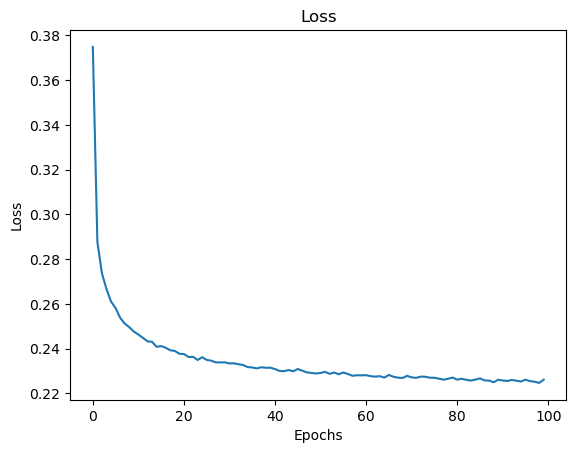

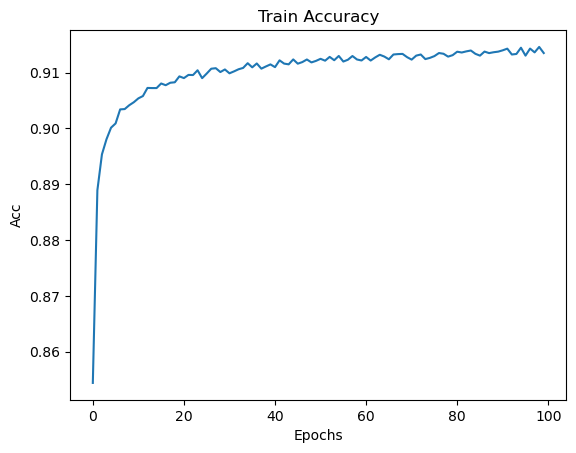

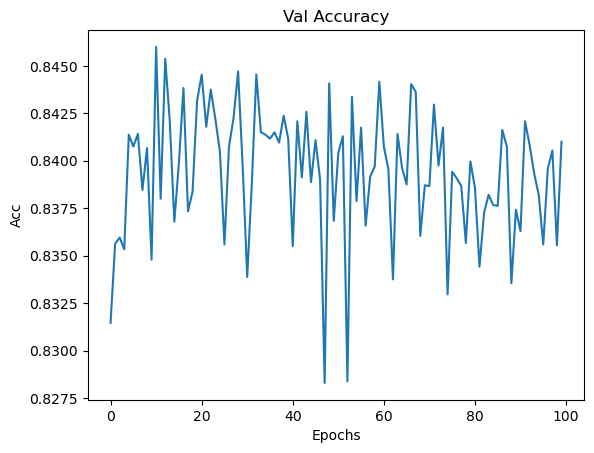

In [28]:
import matplotlib.pyplot as plt


plt.plot(train_losses)
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()


plt.plot(train_accuracies)
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.show()


plt.plot(test_accuracies)
plt.title("Val Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.show()



In [23]:
import os
import cv2
from PIL import Image

import numpy as np

true_values = []
pred_values = []

i = 0


for image, label in test_dataset:

    true_values.append(label)

    cropped_image_dinov2 = processor(images=image, return_tensors="pt").to(device)

    with torch.no_grad():
        output = model(**cropped_image_dinov2)
        logits = output.logits
        #print(logits)
        predicted_class = logits.argmax(-1).item()

    #print("Classe prevista: " + str(class_coding[predicted_class]))

    pred_values.append(predicted_class)

    print(f"Image {i}")

    i+=1


Image 0
Image 1
Image 2
Image 3
Image 4
Image 5
Image 6
Image 7
Image 8
Image 9
Image 10
Image 11
Image 12
Image 13
Image 14
Image 15
Image 16
Image 17
Image 18
Image 19
Image 20
Image 21
Image 22
Image 23
Image 24
Image 25
Image 26
Image 27
Image 28
Image 29
Image 30
Image 31
Image 32
Image 33
Image 34
Image 35
Image 36
Image 37
Image 38
Image 39
Image 40
Image 41
Image 42
Image 43
Image 44
Image 45
Image 46
Image 47
Image 48
Image 49
Image 50
Image 51
Image 52
Image 53
Image 54
Image 55
Image 56
Image 57
Image 58
Image 59
Image 60
Image 61
Image 62
Image 63
Image 64
Image 65
Image 66
Image 67
Image 68
Image 69
Image 70
Image 71
Image 72
Image 73
Image 74
Image 75
Image 76
Image 77
Image 78
Image 79
Image 80
Image 81
Image 82
Image 83
Image 84
Image 85
Image 86
Image 87
Image 88
Image 89
Image 90
Image 91
Image 92
Image 93
Image 94
Image 95
Image 96
Image 97
Image 98
Image 99
Image 100
Image 101
Image 102
Image 103
Image 104
Image 105
Image 106
Image 107
Image 108
Image 109
Image 110


The channel dimension is ambiguous. Got image shape (3, 5, 3). Assuming channels are the first dimension.


Image 8587
Image 8588
Image 8589
Image 8590
Image 8591
Image 8592
Image 8593
Image 8594
Image 8595
Image 8596
Image 8597
Image 8598
Image 8599
Image 8600
Image 8601
Image 8602
Image 8603
Image 8604
Image 8605
Image 8606
Image 8607
Image 8608
Image 8609
Image 8610
Image 8611
Image 8612
Image 8613
Image 8614
Image 8615
Image 8616
Image 8617
Image 8618
Image 8619
Image 8620
Image 8621
Image 8622
Image 8623
Image 8624
Image 8625
Image 8626
Image 8627
Image 8628
Image 8629
Image 8630
Image 8631
Image 8632
Image 8633
Image 8634
Image 8635
Image 8636
Image 8637
Image 8638
Image 8639
Image 8640
Image 8641
Image 8642
Image 8643
Image 8644
Image 8645
Image 8646
Image 8647
Image 8648
Image 8649
Image 8650
Image 8651
Image 8652
Image 8653
Image 8654
Image 8655
Image 8656
Image 8657
Image 8658
Image 8659
Image 8660
Image 8661
Image 8662
Image 8663
Image 8664
Image 8665
Image 8666
Image 8667
Image 8668
Image 8669
Image 8670
Image 8671
Image 8672
Image 8673
Image 8674
Image 8675
Image 8676
Image 8677

In [24]:
conf_matrix = [
    [0, 0, 0],
    [0, 0, 0],
    [0, 0, 0]
]

for i in range(len(true_values)):
    conf_matrix[true_values[i]][pred_values[i]] += 1

In [25]:
conf_matrix

[[3391, 439, 170], [300, 3611, 89], [117, 75, 3809]]

In [26]:
from sklearn.metrics import f1_score, precision_score, recall_score

f1_score_model = f1_score(true_values, pred_values, average=None)
precision_model = precision_score(true_values, pred_values, average=None)
recall_model = recall_score(true_values, pred_values, average=None)

In [27]:
print(f"Precision (BlackRot, Esca, LeafBlight): {precision_model}") 
print(f"Average Precision: {sum(precision_model)/len(precision_model)}") 

Precision (BlackRot, Esca, LeafBlight): [0.8904937  0.87539394 0.93633235]
Average Precision: 0.9007399956406985


In [29]:
print(f"Recall (BlackRot, Esca, LeafBlight): {recall_model}") 
print(f"Average Recall: {sum(recall_model)/len(recall_model)}") 

Recall (BlackRot, Esca, LeafBlight): [0.84775  0.90275  0.952012]
Average Recall: 0.9008373323335833


In [30]:
print(f"F1-Scores (BlackRot, Esca, LeafBlight): {f1_score_model}") 
print(f"Average F1-Score: {sum(f1_score_model)/len(f1_score_model)}") 

F1-Scores (BlackRot, Esca, LeafBlight): [0.86859631 0.88886154 0.94410708]
Average F1-Score: 0.9005216421341444
